# Protein binding and interface assay context

## 1. Data acquisition

ProteinGym v1.3 supplies human deep mutational scanning measurements, assay metadata and AlphaFold structures. The metadata revision and all file hashes are specified below. UniProt canonical protein sequences were retrieved November 9, 2026. AlphaMissense uses its released substitution scores; no model is trained or fine-tuned.


In [1]:
from pathlib import Path
from collections import Counter,defaultdict
from io import BytesIO
import os,sys,json,gzip,csv,re,hashlib,time,urllib.request,ssl,zipfile,math,platform
for key in ['OMP_NUM_THREADS','OPENBLAS_NUM_THREADS','MKL_NUM_THREADS']:os.environ[key]='1'
import numpy as np
import pandas as pd
from scipy.stats import spearmanr,wilcoxon
from sklearn.metrics import roc_auc_score,average_precision_score
from Bio.Align import substitution_matrices
import statsmodels.api as sm
import statsmodels.formula.api as smf
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display,Image,Markdown
RAW=Path(os.environ.get('AM_RAW_INPUTS','am_public_inputs')).expanduser().resolve()
OUTPUT=Path('calculated_outputs').resolve();RAW.mkdir(parents=True,exist_ok=True);OUTPUT.mkdir(parents=True,exist_ok=True)
STARTED=time.time()
pd.set_option('display.max_colwidth',100)
def show_figure(fig):
    buffer=BytesIO();fig.savefig(buffer,format='png',dpi=150,bbox_inches='tight');display(Image(data=buffer.getvalue()))


In [2]:
SOURCES = [{'id': 'am_aa',
  'path': 'inputs/raw/AlphaMissense_aa_substitutions.tsv.gz',
  'url': 'https://storage.googleapis.com/dm_alphamissense/AlphaMissense_aa_substitutions.tsv.gz',
  'sha256': 'bc18d954a9aa6b9efab8e40d6d1912e32b774906cd3846a1f51066588e9c176d',
  'bytes': 1207278510},
 {'id': 'proteingym_dms',
  'path': 'inputs/raw/DMS_ProteinGym_v1.3_substitutions.zip',
  'url': 'https://marks.hms.harvard.edu/proteingym/ProteinGym_v1.3/DMS_ProteinGym_substitutions.zip',
  'sha256': '3a83766254ac9ac9984ec25cb73c6e010ea4418f5e35f143933e6b6e6473b921',
  'bytes': 43021128},
 {'id': 'proteingym_af2',
  'path': 'inputs/raw/ProteinGym_v1.3_AF2_structures.zip',
  'url': 'https://marks.hms.harvard.edu/proteingym/ProteinGym_v1.3/ProteinGym_AF2_structures.zip',
  'sha256': 'ed8611bf12cfb840ea1c2561be36254901008610a49b1be475e917b6c5d6d56a',
  'bytes': 19173248},
 {'id': 'proteingym_metadata',
  'path': 'inputs/raw/DMS_substitutions.csv',
  'url': 'https://raw.githubusercontent.com/OATML-Markslab/ProteinGym/144fe22b07dfaeec2b366f2346203a9838a55b4c/reference_files/DMS_substitutions.csv',
  'sha256': 'a8f498011532a74aa9fe556a50555a75e928c5837d19c06a87592ae04049b308',
  'bytes': None},
 {'id': 'uniprot_human',
  'path': 'uniprot_reviewed_human_20261109.fasta.gz',
  'url': 'https://rest.uniprot.org/uniprotkb/stream?query=%28proteome%3AUP000005640%29%20AND%20%28reviewed%3Atrue%29&format=fasta&compressed=true',
  'sha256': '97e06262e2679f9541d1b10245f480f1cd82e00a79e2c99db032e6669dd5b48d',
  'bytes': 7505116}]

def sha256_file(path):
    h=hashlib.sha256()
    with Path(path).open('rb') as f:
        for block in iter(lambda:f.read(8*1024*1024),b''):h.update(block)
    return h.hexdigest()
def acquire(source):
    p=RAW/Path(source['path']).name
    if not p.exists():
        partial=p.with_name(p.name+'.notebook-part')
        req=urllib.request.Request(source['url'],headers={'User-Agent':'AlphaMissense-analysis/1.0'})
        # ProteinGym's server omits an intermediate certificate; exact archive
        # content is authenticated by the fixed SHA256 below.
        context=ssl._create_unverified_context() if 'marks.hms.harvard.edu' in source['url'] and source.get('sha256') else None
        with urllib.request.urlopen(req,timeout=180,context=context) as r,partial.open('wb') as f:
            while True:
                b=r.read(4*1024*1024)
                if not b:break
                f.write(b)
        if source.get('sha256') and sha256_file(partial)!=source['sha256']:raise ValueError('Download checksum mismatch: '+p.name)
        if source.get('bytes') and partial.stat().st_size!=source['bytes']:raise ValueError('Download size mismatch: '+p.name)
        partial.replace(p)
    h=sha256_file(p)
    if source.get('sha256') and h!=source['sha256']:raise ValueError('Input checksum mismatch: '+p.name)
    if source.get('bytes') and p.stat().st_size!=source['bytes']:raise ValueError('Input size mismatch: '+p.name)
    return dict(path=p.name,url=source['url'],sha256=h,bytes=p.stat().st_size)
source_receipts=[acquire(s) for s in SOURCES]
display(pd.DataFrame(source_receipts))


,path,url,sha256,bytes
0,AlphaMissense_aa_substitutions.tsv.gz,https://storage.googleapis.com/dm_alphamissense/AlphaMissense_aa_substitutions.tsv.gz,bc18d954a9aa6b9efab8e40d6d1912e32b774906cd3846a1f51066588e9c176d,1207278510
1,DMS_ProteinGym_v1.3_substitutions.zip,https://marks.hms.harvard.edu/proteingym/ProteinGym_v1.3/DMS_ProteinGym_substitutions.zip,3a83766254ac9ac9984ec25cb73c6e010ea4418f5e35f143933e6b6e6473b921,43021128
2,ProteinGym_v1.3_AF2_structures.zip,https://marks.hms.harvard.edu/proteingym/ProteinGym_v1.3/ProteinGym_AF2_structures.zip,ed8611bf12cfb840ea1c2561be36254901008610a49b1be475e917b6c5d6d56a,19173248
3,DMS_substitutions.csv,https://raw.githubusercontent.com/OATML-Markslab/ProteinGym/144fe22b07dfaeec2b366f2346203a9838a5...,a8f498011532a74aa9fe556a50555a75e928c5837d19c06a87592ae04049b308,208734
4,uniprot_reviewed_human_20261109.fasta.gz,https://rest.uniprot.org/uniprotkb/stream?query=%28proteome%3AUP000005640%29%20AND%20%28reviewed...,97e06262e2679f9541d1b10245f480f1cd82e00a79e2c99db032e6669dd5b48d,7505116


## 2. Raw processing

Read each human assay directly from the public archive. Retain standard single substitutions outside the start position, validate the wild-type residue, map entry names to reviewed human UniProt records, map each local assay position to the reviewed UniProt sequence by exact substring or matching-residue local alignment (match 2, mismatch −1, gap open −10, extension −0.5), and require an unambiguous AlphaMissense score. Unmapped or conflicting records are counted and excluded. Protein partitions are determined from the first 32 bits of SHA256 of `spectra-alphamissense-dms-v1|` plus the entry name, modulo 10; values 0–3 form discovery.


In [3]:
# Public canonical sequence records provide an accession/entry-name map.
entry_accessions=defaultdict(list);canonical={};acc=None;buf=[]
with gzip.open(RAW/'uniprot_reviewed_human_20261109.fasta.gz','rt') as f:
    for line in f:
        line=line.strip()
        if line.startswith('>'):
            if acc:canonical[acc]=''.join(buf)
            fields=line.split()[0].split('|');acc=fields[1];entry_accessions[fields[2]].append(acc);buf=[]
        else:buf.append(line)
    if acc:canonical[acc]=''.join(buf)
AA_RE=re.compile(r'^([ACDEFGHIKLMNPQRSTVWY])(\d+)([ACDEFGHIKLMNPQRSTVWY])$')
def protein_split(entry: str) -> str:
    value = int.from_bytes(hashlib.sha256(
        ("spectra-alphamissense-dms-v1|" + entry).encode()).digest()[:4], "big") % 10
    return "discovery" if value < 4 else "confirmation"

def load_dms_rows() -> tuple[pd.DataFrame, dict, Counter]:
    ref = pd.read_csv(RAW / "DMS_substitutions.csv")
    ref = ref[ref.taxon.eq("Human")].copy()
    candidates = dict(entry_accessions)
    qc = Counter()
    rows = []
    archive = RAW / "DMS_ProteinGym_v1.3_substitutions.zip"
    with zipfile.ZipFile(archive) as zf:
        for _, meta in ref.iterrows():
            if meta.UniProt_ID not in candidates:
                qc["assays_without_canonical_accession"] += 1
                continue
            name = f"DMS_ProteinGym_substitutions/{meta.DMS_filename}"
            with zf.open(name) as handle:
                assay = pd.read_csv(handle)
            for record in assay.itertuples(index=False):
                qc["dms_rows_scanned"] += 1
                mutant = str(record.mutant)
                match = AA_RE.match(mutant)
                if not match:
                    qc["excluded_non_single_or_noncanonical_mutant"] += 1
                    continue
                ref_aa, pos_text, alt_aa = match.groups()
                pos = int(pos_text)
                if pos == 1:
                    qc["excluded_start_loss_position1"] += 1
                    continue
                target = str(meta.target_seq)
                if pos > len(target) or target[pos - 1] != ref_aa:
                    qc["excluded_proteingym_reference_mismatch"] += 1
                    continue
                rows.append({
                    "dms_id": meta.DMS_id, "entry_name": meta.UniProt_ID,
                    "protein_partition": protein_split(meta.UniProt_ID),
                    "mutant": mutant, "ref_aa": ref_aa, "aa_pos": pos, "alt_aa": alt_aa,
                    "dms_score": float(record.DMS_score),
                    "dms_score_bin": int(record.DMS_score_bin),
                    "dms_deleterious": 1 - int(record.DMS_score_bin),
                    "selection_type": meta.selection_type,
                    "coarse_selection_type": meta.coarse_selection_type,
                    "msa_neff_l": meta.MSA_Neff_L, "msa_depth_category": meta.MSA_Neff_L_category,
                    "protein_length": len(target),
                })
    df = pd.DataFrame(rows)
    qc["eligible_human_single_mutant_rows"] = len(df)
    qc["human_assays"] = df.dms_id.nunique()
    qc["human_proteins"] = df.entry_name.nunique()
    return df, candidates, qc

def score_keys(df: pd.DataFrame, candidates: dict) -> tuple[dict, Counter]:
    wanted = set()
    for entry, mutant in df[["entry_name", "mutant"]].drop_duplicates().itertuples(index=False):
        for accession in candidates.get(entry, []):
            wanted.add((accession, mutant))
    found = defaultdict(list)
    qc = Counter()
    with gzip.open(RAW / "AlphaMissense_aa_substitutions.tsv.gz", "rt", newline="") as handle:
        reader = csv.reader(handle, delimiter="\t")
        for f in reader:
            if not f or f[0].startswith("#") or f[0] == "uniprot_id":
                continue
            qc["aa_score_rows_scanned"] += 1
            key = (f[0], f[1])
            if key in wanted:
                found[key].append((float(f[2]), f[3]))
    qc["wanted_accession_mutation_keys"] = len(wanted)
    qc["matched_accession_mutation_keys"] = len(found)
    return found, qc

def resolve_scores(df: pd.DataFrame, candidates: dict, found: dict, qc: Counter) -> pd.DataFrame:
    accessions, scores, classes = [], [], []
    for entry, mutant in df[["entry_name", "mutant"]].itertuples(index=False):
        options = []
        for accession in candidates.get(entry, []):
            for score, cls in found.get((accession, mutant), []):
                options.append((accession, score, cls))
        unique = {(round(x[1], 8), x[2]) for x in options}
        if not options:
            accessions.append(None); scores.append(np.nan); classes.append(None)
            continue
        if len(unique) > 1:
            qc["ambiguous_accession_score_rows"] += 1
            accessions.append(None); scores.append(np.nan); classes.append(None)
            continue
        accessions.append("|".join(sorted({x[0] for x in options})))
        scores.append(options[0][1]); classes.append(options[0][2])
    out = df.copy()
    out["uniprot_accession"] = accessions
    out["am_pathogenicity"] = scores
    out["am_class"] = classes
    qc["dms_rows_with_am_score"] = int(out.am_pathogenicity.notna().sum())
    return out[out.am_pathogenicity.notna()].copy()

from Bio.Align import PairwiseAligner
metadata=pd.read_csv(RAW/'DMS_substitutions.csv').set_index('DMS_id')
def residue_map(query,reference):
    offset=reference.find(query)
    if offset>=0:return {i+1:i+1+offset for i in range(len(query))},'exact substring'
    aligner=PairwiseAligner();aligner.mode='local';aligner.match_score=2;aligner.mismatch_score=-1;aligner.open_gap_score=-10;aligner.extend_gap_score=-.5
    alignment=aligner.align(reference,query)[0];mapping={}
    for (ra,rb),(qa,qb) in zip(*alignment.aligned):
        for r,q in zip(range(ra,rb),range(qa,qb)):
            if reference[r]==query[q]:mapping[q+1]=r+1
    return mapping,'local alignment, matching residues only'
df,candidates,qc=load_dms_rows()
accessions={a for entry in df.entry_name.unique() for a in candidates.get(entry,[])}
released=defaultdict(dict);ambiguous_scores=set()
with gzip.open(RAW/'AlphaMissense_aa_substitutions.tsv.gz','rt') as stream:
    for line in stream:
        if line.startswith('#') or line.startswith('uniprot_id'):continue
        fields=line.rstrip().split('\t')
        if fields[0] not in accessions:continue
        match=AA_RE.fullmatch(fields[1])
        if match:
            key=(match[1],int(match[2]),match[3]);value=(float(fields[2]),fields[3])
            old=released[fields[0]].get(key)
            if old is not None and old!=value:ambiguous_scores.add((fields[0],key))
            released[fields[0]][key]=value
qc['conflicting released substitution keys']=len(ambiguous_scores)
position_maps={};map_qc=[]
for aid,g in df.groupby('dms_id'):
    query=str(metadata.loc[aid,'target_seq']);entry=g.entry_name.iloc[0]
    for accession in candidates.get(entry,[]):
        reference=canonical.get(accession,'')
        if not reference:continue
        mapping,method=residue_map(query,reference);position_maps[aid,accession]=mapping
        map_qc.append({'assay':aid,'accession':accession,'target_length':len(query),'canonical_length':len(reference),'mapped_matching_positions':len(mapping),'mapping_method':method})
scored=[]
for row in df.to_dict('records'):
    choices=[]
    for accession in candidates.get(row['entry_name'],[]):
        position=position_maps.get((row['dms_id'],accession),{}).get(row['aa_pos'])
        if position is None or canonical[accession][position-1]!=row['ref_aa']:continue
        key=(row['ref_aa'],position,row['alt_aa'])
        if (accession,key) in ambiguous_scores:continue
        hit=released[accession].get(key)
        if hit:choices.append((accession,position,hit[0],hit[1]))
    signatures={(position,round(score,8),label) for _,position,score,label in choices}
    if len(signatures)!=1:
        qc['missing_or_ambiguous_canonical_score']+=1;continue
    accession,position,score,label=choices[0]
    scored.append({**row,'uniprot_accession':'|'.join(sorted({c[0] for c in choices})),'canonical_mutant':row['ref_aa']+str(position)+row['alt_aa'],'canonical_position':position,'am_pathogenicity':score,'am_class':label})
df=pd.DataFrame(scored);B62=substitution_matrices.load('BLOSUM62')
df['blosum_pathogenicity']=[-float(B62[a,b]) for a,b in zip(df.ref_aa,df.alt_aa)]
qc['DMS rows with canonical score']=len(df);mapping_qc=pd.DataFrame(map_qc);mapping_qc.to_csv(OUTPUT/'canonical_mapping.csv',index=False)
display(pd.Series(dict(qc),name='count').to_frame());display(mapping_qc)
display(df[['dms_id','entry_name','mutant','canonical_mutant','dms_score','dms_deleterious','protein_partition']].head())


,count
dms_rows_scanned,479142
excluded_non_single_or_noncanonical_mutant,156166
excluded_start_loss_position1,623
assays_without_canonical_accession,2
eligible_human_single_mutant_rows,322353
human_assays,94
human_proteins,80
conflicting released substitution keys,0
missing_or_ambiguous_canonical_score,1298
DMS rows with canonical score,321055


,assay,accession,target_length,canonical_length,mapped_matching_positions,mapping_method
0,A4_HUMAN_Seuma_2022,P05067,770,770,770,exact substring
1,ACE2_HUMAN_Chan_2020,Q9BYF1,805,805,805,exact substring
2,ADRB2_HUMAN_Jones_2020,P07550,413,413,413,exact substring
3,AICDA_HUMAN_Gajula_2014_3cycles,Q9GZX7,198,198,198,exact substring
4,AMFR_HUMAN_Tsuboyama_2023_4G3O,Q9UKV5,47,643,43,"local alignment, matching residues only"
...,...,...,...,...,...,...
89,UBE4B_HUMAN_Tsuboyama_2023_3L1X,O95155,69,1302,69,exact substring
90,UBR5_HUMAN_Tsuboyama_2023_1I2T,O95071,58,2799,58,exact substring
91,VKOR1_HUMAN_Chiasson_2020_abundance,Q9BQB6,163,163,163,exact substring
92,VKOR1_HUMAN_Chiasson_2020_activity,Q9BQB6,163,163,163,exact substring


,dms_id,entry_name,mutant,canonical_mutant,dms_score,dms_deleterious,protein_partition
0,A4_HUMAN_Seuma_2022,A4_HUMAN,A673C,A673C,-1.018869,0,discovery
1,A4_HUMAN_Seuma_2022,A4_HUMAN,A673D,A673D,-0.605052,0,discovery
2,A4_HUMAN_Seuma_2022,A4_HUMAN,A673E,A673E,-0.590857,0,discovery
3,A4_HUMAN_Seuma_2022,A4_HUMAN,A673F,A673F,-0.216833,0,discovery
4,A4_HUMAN_Seuma_2022,A4_HUMAN,A673G,A673G,0.268496,0,discovery


## 3. Axis and levels

The input-side grouping is ProteinGym’s declared selection mechanism. Binding assays form the specific interface-related group; the assay category does not claim that every assayed residue is a physical interface residue. Protein-disjoint partitions prevent reuse of a protein across discovery and confirmation.


In [4]:
df['axis_level']=df.coarse_selection_type.fillna('Unspecified')
display(df.groupby(['protein_partition','axis_level']).agg(rows=('mutant','size'),proteins=('entry_name','nunique'),assays=('dms_id','nunique')))


rows  proteins  assays
protein_partition axis_level                                
confirmation      Activity           52675        13      15
                  Binding            15066         5       5
                  Expression         22187         8       8
                  OrganismalFitness  59655        14      14
                  Stability          19068        18      18
discovery         Activity           29007         5       5
                  Binding             6503         2       2
                  Expression         31542         6       6
                  OrganismalFitness  80673        12      16
                  Stability           4679         5       5

## 4. Model results and reference

Released AlphaMissense scores are joined by accession and substitution. Negative BLOSUM62 is evaluated on identical variants. DMS scores are oriented so greater fitness is better, and deleterious labels equal one minus ProteinGym’s binary score. Structure confidence and alignment depth are input-side controls. No training or fine-tuning is performed.


In [5]:
from Bio.SeqUtils import seq1
structures={}
with zipfile.ZipFile(RAW/'ProteinGym_v1.3_AF2_structures.zip') as archive:
    names=set(archive.namelist())
    for entry in sorted(df.entry_name.unique()):
        member=f'ProteinGym_AF2_structures/{entry}.pdb'
        if member not in names:continue
        residues={}
        for line in archive.read(member).decode().splitlines():
            if line.startswith('ATOM') and line[12:16].strip()=='CA':
                key=(line[21],line[22:27]);residues.setdefault(key,(seq1(line[17:20],custom_map={'MSE':'M'}),float(line[60:66])))
        structures[entry]=(''.join(x[0] for x in residues.values()),[x[1] for x in residues.values()])
structure_maps={}
for aid,g in df.groupby('dms_id'):
    entry=g.entry_name.iloc[0]
    if entry in structures:structure_maps[aid]=residue_map(str(metadata.loc[aid,'target_seq']),structures[entry][0])[0]
values=[]
for row in df.itertuples():
    position=structure_maps.get(row.dms_id,{}).get(row.aa_pos)
    values.append(structures[row.entry_name][1][position-1] if position else np.nan)
df['af2_plddt']=values;df['af2_low_confidence_lt50']=df.af2_plddt<50
print('Residues with mapped structure confidence:',int(df.af2_plddt.notna().sum()),'of',len(df))


Residues with mapped structure confidence: 321055 of 321055


## 5. Curves and controls

Calculate each assay’s Spearman correlation between predicted benignness and DMS fitness. Summaries weight assays equally; intervals resample proteins to respect dependence. Display category support and paired BLOSUM62 controls. Binding support must include at least three independent proteins in each partition to sustain a general claim.


,partition,category,score,assays,proteins,median_rho,ci_low,ci_high
0,confirmation,Activity,am_pathogenicity,15,13,0.580911,0.463841,0.651411
1,confirmation,Activity,blosum_pathogenicity,15,13,0.219228,0.183210,0.367380
2,confirmation,Binding,am_pathogenicity,5,5,0.365869,0.248442,0.570673
3,confirmation,Binding,blosum_pathogenicity,5,5,0.180268,0.141697,0.400314
4,confirmation,Expression,am_pathogenicity,8,8,0.501457,0.127261,0.604374
5,confirmation,Expression,blosum_pathogenicity,8,8,0.240194,0.212295,0.335687
6,confirmation,OrganismalFitness,am_pathogenicity,14,14,0.450910,0.335484,0.550139
7,confirmation,OrganismalFitness,blosum_pathogenicity,14,14,0.158779,0.109442,0.260563
8,confirmation,Stability,am_pathogenicity,18,18,0.454929,0.374128,0.489072
9,confirmation,Stability,blosum_pathogenicity,18,18,0.146470,0.113240,0.187280


,partition,assay,protein,category,n,median_plddt,msa_neff_l
0,confirmation,ACE2_HUMAN_Chan_2020,ACE2_HUMAN,Binding,2223,94.660,1.97
2,confirmation,AICDA_HUMAN_Gajula_2014_3cycles,AICDA_HUMAN,Activity,209,62.410,18.40
4,confirmation,B2L11_HUMAN_Dutta_2010_binding-Mcl-1,B2L11_HUMAN,Binding,170,91.315,0.45
6,confirmation,BRCA2_HUMAN_Erwood_2022_HEK293T,BRCA2_HUMAN,OrganismalFitness,265,87.010,0.02
8,confirmation,CALM1_HUMAN_Weile_2017,CALM1_HUMAN,OrganismalFitness,1813,83.950,190.77
...,...,...,...,...,...,...,...
178,discovery,TNKS2_HUMAN_Tsuboyama_2023_5JRT,TNKS2_HUMAN,Stability,1062,97.495,195.89
180,discovery,TPK1_HUMAN_Weile_2017,TPK1_HUMAN,OrganismalFitness,3181,98.520,29.93
182,discovery,VKOR1_HUMAN_Chiasson_2020_abundance,VKOR1_HUMAN,Expression,2695,91.290,29.05
184,discovery,VKOR1_HUMAN_Chiasson_2020_activity,VKOR1_HUMAN,Activity,697,91.400,29.05


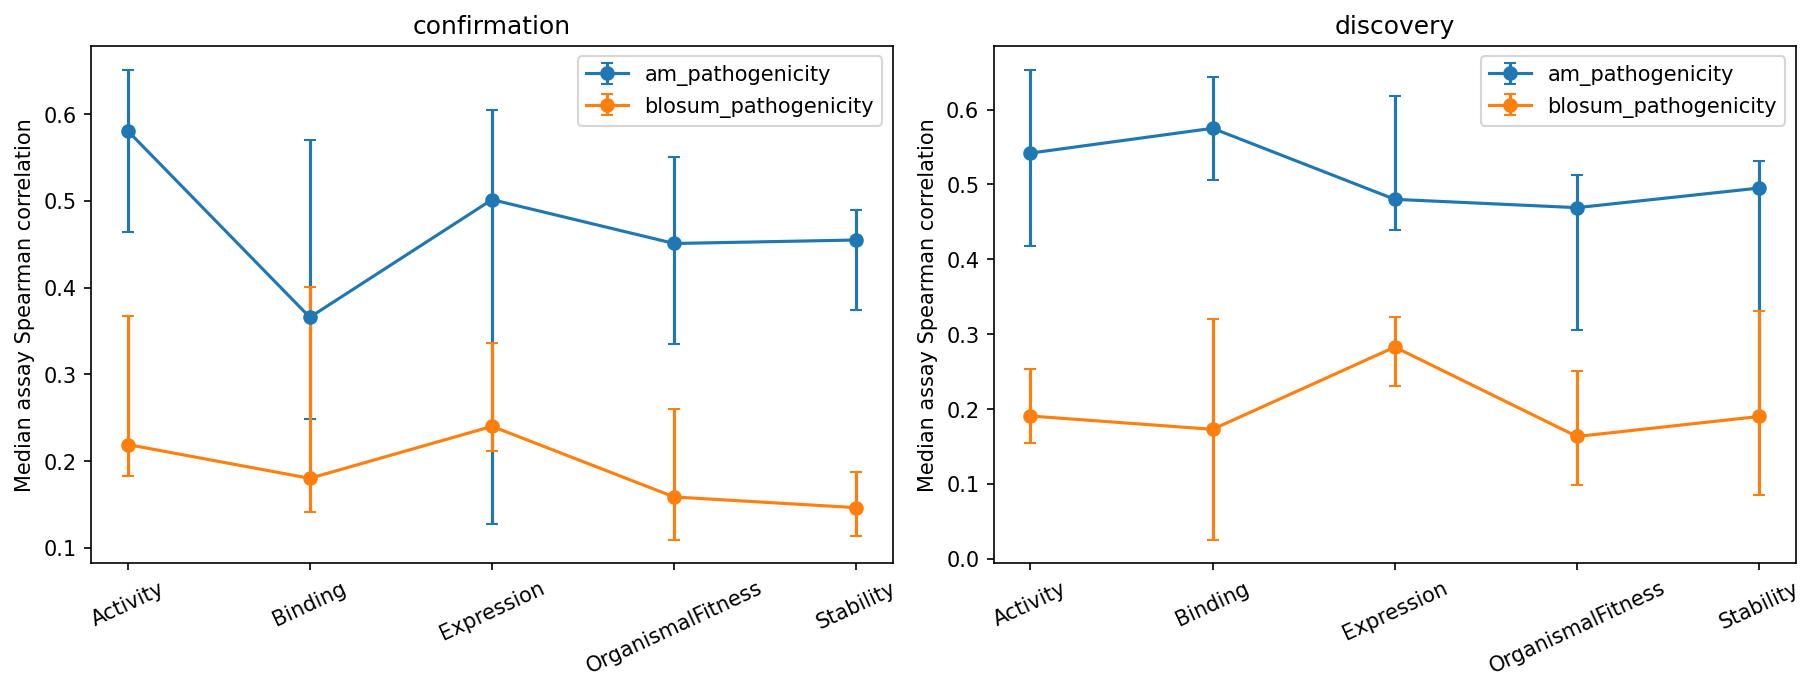

In [6]:
rows=[]
for (part,assay),g in df.groupby(['protein_partition','dms_id']):
    if len(g)<20 or g.dms_score.nunique()<2:continue
    for score in ['am_pathogenicity','blosum_pathogenicity']:
        rows.append({'partition':part,'assay':assay,'protein':g.entry_name.iloc[0],'category':g.axis_level.iloc[0],'score':score,'n':len(g),'rho':float(spearmanr(-g[score],g.dms_score).statistic),'median_plddt':g.af2_plddt.median(),'msa_neff_l':g.msa_neff_l.median()})
assays=pd.DataFrame(rows);rng=np.random.default_rng(20260715);rows=[]
for (part,category,score),g in assays.groupby(['partition','category','score']):
    proteins=g.protein.unique();draws=[]
    for _ in range(2000):
        chosen=rng.choice(proteins,len(proteins),replace=True);v=np.concatenate([g.loc[g.protein==p,'rho'].to_numpy() for p in chosen]);draws.append(np.median(v))
    lo,hi=np.quantile(draws,[.025,.975]);rows.append({'partition':part,'category':category,'score':score,'assays':len(g),'proteins':len(proteins),'median_rho':g.rho.median(),'ci_low':lo,'ci_high':hi})
curves=pd.DataFrame(rows);contrasts=assays;control=assays[['partition','assay','protein','category','n','median_plddt','msa_neff_l']].drop_duplicates();display(curves);display(control)
fig,axes=plt.subplots(1,2,figsize=(12,4.5),layout='constrained')
for ax,(part,g) in zip(axes,curves.groupby('partition')):
    categories=sorted(g.category.unique())
    for score,s in g.groupby('score'):
        s=s.set_index('category').reindex(categories);y=s.median_rho.to_numpy();ax.errorbar(range(len(categories)),y,yerr=np.maximum(0,np.array([y-s.ci_low,s.ci_high-y])),marker='o',capsize=3,label=score)
    ax.set(xticks=range(len(categories)),xticklabels=categories,ylabel='Median assay Spearman correlation',title=part);ax.tick_params(axis='x',labelrotation=25);ax.legend()
show_figure(fig);plt.close(fig)


## 6. Result and decision

An assay-category association cannot identify physical binding interfaces by itself. The decision checks independent protein support before interpreting the calculated binding results.


In [7]:
binding=curves[(curves.category.astype(str).str.contains('binding',case=False)) & (curves.score=='am_pathogenicity')]
support=binding.groupby('partition').proteins.sum().reindex(['discovery','confirmation'],fill_value=0)
if (support>=3).all():decision='Binding assays have adequate independent protein support for a descriptive assay-category comparison. Physical interface localization remains untested because assay mechanism is not residue-interface annotation.'
else:decision='Do not retain binding assay category as a general interface axis: the displayed binding subset lacks at least three independent proteins in both partitions. The calculated assay results remain descriptive.'
print(decision);display(binding)


Do not retain binding assay category as a general interface axis: the displayed binding subset lacks at least three independent proteins in both partitions. The calculated assay results remain descriptive.


,partition,category,score,assays,proteins,median_rho,ci_low,ci_high
2,confirmation,Binding,am_pathogenicity,5,5,0.365869,0.248442,0.570673
12,discovery,Binding,am_pathogenicity,2,2,0.574999,0.506551,0.643447


In [8]:
df.to_csv(OUTPUT/'individual_dms_variants.csv.gz',index=False,compression='gzip')
curves.to_csv(OUTPUT/'curves.csv',index=False);contrasts.to_csv(OUTPUT/'contrasts.csv',index=False);control.to_csv(OUTPUT/'controls.csv',index=False)
receipt={'sources':source_receipts,'decision':decision,'rows':len(df),'assays':df.dms_id.nunique(),'proteins':df.entry_name.nunique(),'host':platform.node(),'outputs':{p.name:sha256_file(p) for p in OUTPUT.glob('*.csv*')},'elapsed_seconds':time.time()-STARTED}
(OUTPUT/'execution.json').write_text(json.dumps(receipt,indent=2)+'\n')


2345